# 04 — Bayesian hyperparameter optimisation (XGBoost)

XGBoost was selected for tuning from the model comparison (`03_model_comparison.ipynb`): it is among the top
models on Top-1, has good probability quality (log loss, which the HMM uses), a small train-vs-CV gap, and fits in
seconds, which keeps a Bayesian search affordable.

**Method** (`pathsnap/hpo/xgb_optuna.py`)
- Optuna with the **TPE sampler** (Bayesian: models good and bad regions of the space from past trials, samples
  where improvement is likely), seed 42, 10 random start-up trials.
- **Objective**: mean observation-level Top-1 accuracy over the same 5-fold `GroupKFold` on the 80 train trips
  (grouped by `trip_id`). Macro F1 and log loss are recorded per trial.
- **Median pruner**: stops a trial whose running fold mean falls below the median of earlier trials.
- Trial 0 is the untuned configuration.
- Student-test data is used only after the search, to compare tuned vs untuned; evaluator data is never used.
- The study is saved in `results/hpo/xgb_study.db` (full search record, resumable).

In [1]:
# --- setup: find the repo, check the saved study ---
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pathsnap" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import optuna
from IPython.display import Image, display
from pathsnap.config import RESULTS_DIR
from pathsnap.hpo.xgb_optuna import load_study, BASELINE
from pathsnap.viz import hpo_plots

H = RESULTS_DIR / "hpo"
if not (H / "xgb_study.db").exists():
    raise RuntimeError("No study found. Run: python -m pathsnap.hpo.xgb_optuna --trials 50 "
                       "and then python -m pathsnap.hpo.xgb_optuna --refit")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
study = load_study()
optuna.logging.set_verbosity(optuna.logging.WARNING)

/run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[I 2026-11-18 14:11:45,307] Using an existing study with `study_name='xgb_top1'` instead of creating a new one.


## 1. Search space

In [2]:
space = pd.DataFrame([
    ("n_estimators", "int 100-1000, step 50", "boosting rounds; more rounds fit more but can overfit"),
    ("learning_rate", "float 0.01-0.3, log", "shrinkage per round; trades off against n_estimators"),
    ("max_depth", "int 3-10", "interaction depth of each tree"),
    ("min_child_weight", "float 1-50, log", "minimum hessian per leaf; larger = smoother model"),
    ("subsample", "float 0.5-1.0", "row sampling per tree (regularisation)"),
    ("colsample_bytree", "float 0.5-1.0", "feature sampling per tree"),
    ("gamma", "float 0-5", "minimum loss reduction to make a split"),
    ("reg_lambda", "float 0.001-10, log", "L2 penalty on leaf weights"),
    ("reg_alpha", "float 0.001-10, log", "L1 penalty on leaf weights"),
], columns=["hyperparameter", "range / distribution", "role"])
space["untuned value"] = space["hyperparameter"].map(BASELINE)
space

,hyperparameter,range / distribution,role,untuned value
0,n_estimators,"int 100-1000, step 50",boosting rounds; more rounds fit more but can ...,400.000
1,learning_rate,"float 0.01-0.3, log",shrinkage per round; trades off against n_esti...,0.050
2,max_depth,int 3-10,interaction depth of each tree,6.000
3,min_child_weight,"float 1-50, log",minimum hessian per leaf; larger = smoother model,1.000
4,subsample,float 0.5-1.0,row sampling per tree (regularisation),1.000
5,colsample_bytree,float 0.5-1.0,feature sampling per tree,1.000
6,gamma,float 0-5,minimum loss reduction to make a split,0.000
7,reg_lambda,"float 0.001-10, log",L2 penalty on leaf weights,1.000
8,reg_alpha,"float 0.001-10, log",L1 penalty on leaf weights,0.001


## 2. Search record

In [3]:
trials = pd.read_csv(H / "xgb_trials.csv")
states = trials["state"].value_counts()
print("trials:", states.to_dict(), "| total search time:", round(trials["duration_s"].sum() / 60, 1), "min")
cols = ["number", "value", "state", "user_attrs_cv_macro_f1", "user_attrs_cv_log_loss", "duration_s"] + \
       [c for c in trials.columns if c.startswith("params_")]
trials[cols].sort_values("value", ascending=False).head(10).round(4)

trials: {'COMPLETE': 39, 'PRUNED': 11} | total search time: 62.5 min


,number,value,state,user_attrs_cv_macro_f1,user_attrs_cv_log_loss,duration_s,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample
14,14,0.9089,PRUNED,NaN,NaN,46.6040,0.9458,2.7372,0.0130,7,6.8187,600,1.6276,2.6432,0.7047
15,15,0.9088,PRUNED,NaN,NaN,38.1819,0.8875,4.3573,0.0311,8,22.7433,600,8.2721,0.8301,0.6170
31,31,0.9040,COMPLETE,0.9449,0.0690,81.7837,0.9609,2.5796,0.0313,9,3.6358,750,0.6000,0.5819,0.7094
48,48,0.9039,COMPLETE,0.9451,0.0686,86.6967,0.9265,3.2832,0.0314,9,1.9958,900,0.1088,2.7474,0.6553
17,17,0.9038,COMPLETE,0.9449,0.0685,77.4486,0.9152,2.8671,0.0281,9,3.3118,700,0.4570,1.0090,0.7148
34,34,0.9038,COMPLETE,0.9447,0.0692,104.7932,0.9903,1.8880,0.0257,9,5.8338,800,0.8960,0.6144,0.6274
24,24,0.9038,COMPLETE,0.9450,0.0685,82.7040,0.8511,3.2370,0.0311,9,3.0586,850,0.2126,3.2045,0.6730
16,16,0.9036,COMPLETE,0.9451,0.0684,76.8440,0.8549,3.1062,0.0270,9,8.0342,650,0.1017,0.4842,0.6134
36,36,0.9036,COMPLETE,0.9446,0.0699,103.9546,0.9579,1.5160,0.0296,9,6.6912,800,0.5451,0.0941,0.6726
43,43,0.9035,COMPLETE,0.9446,0.0696,97.5570,0.9562,1.9795,0.0342,9,9.7149,800,1.8413,0.2692,0.6764


## 3. Best configuration

In [4]:
best = pd.DataFrame({"untuned": pd.Series(BASELINE), "best": pd.Series(study.best_params)})
print(f"best trial #{study.best_trial.number}: CV top-1 {study.best_value:.4f} "
      f"(untuned trial 0: {study.trials[0].value:.4f})")
best

best trial #31: CV top-1 0.9040 (untuned trial 0: 0.9013)


,untuned,best
n_estimators,400.000,750.000000
learning_rate,0.050,0.031276
max_depth,6.000,9.000000
min_child_weight,1.000,3.635785
subsample,1.000,0.709365
colsample_bytree,1.000,0.960874
gamma,0.000,2.579639
reg_lambda,1.000,0.581915
reg_alpha,0.001,0.599953


## 4. Plots

plots -> /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/results/hpo/plots


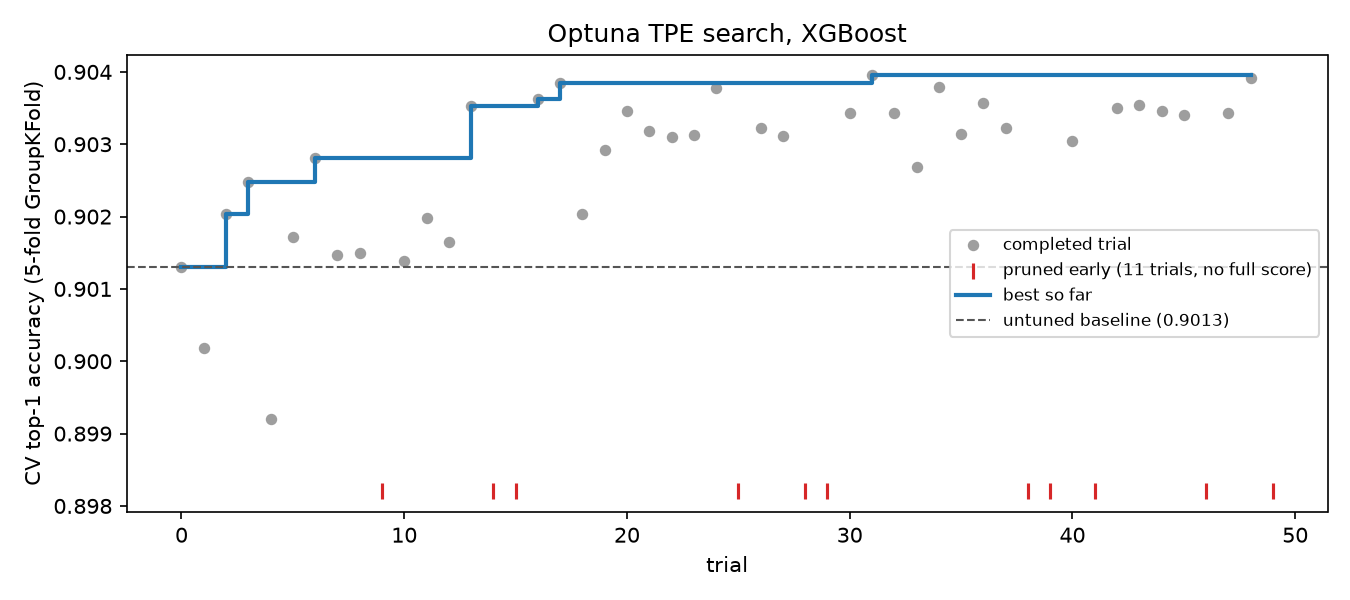

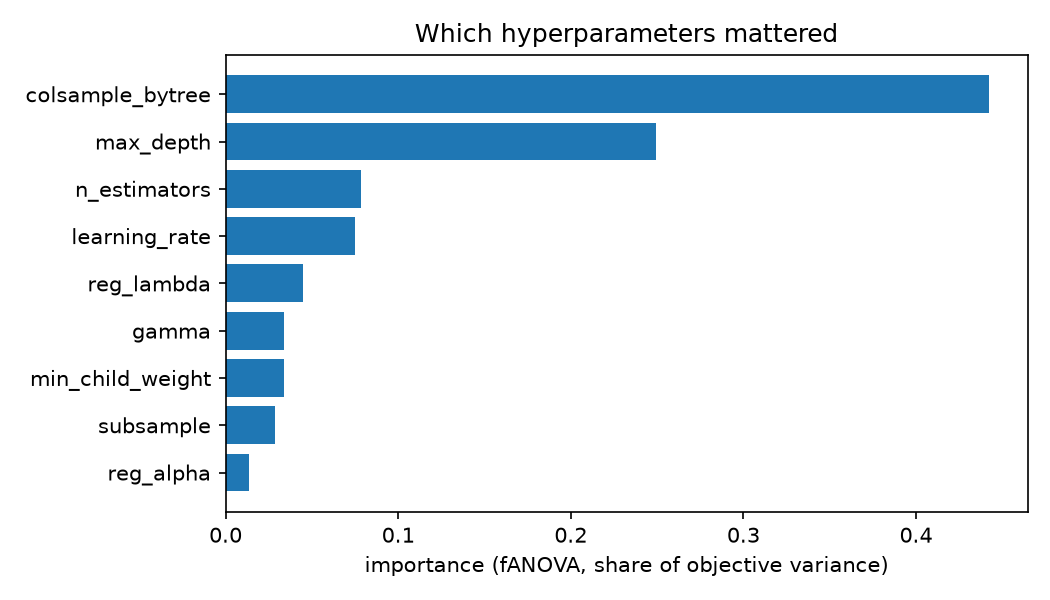

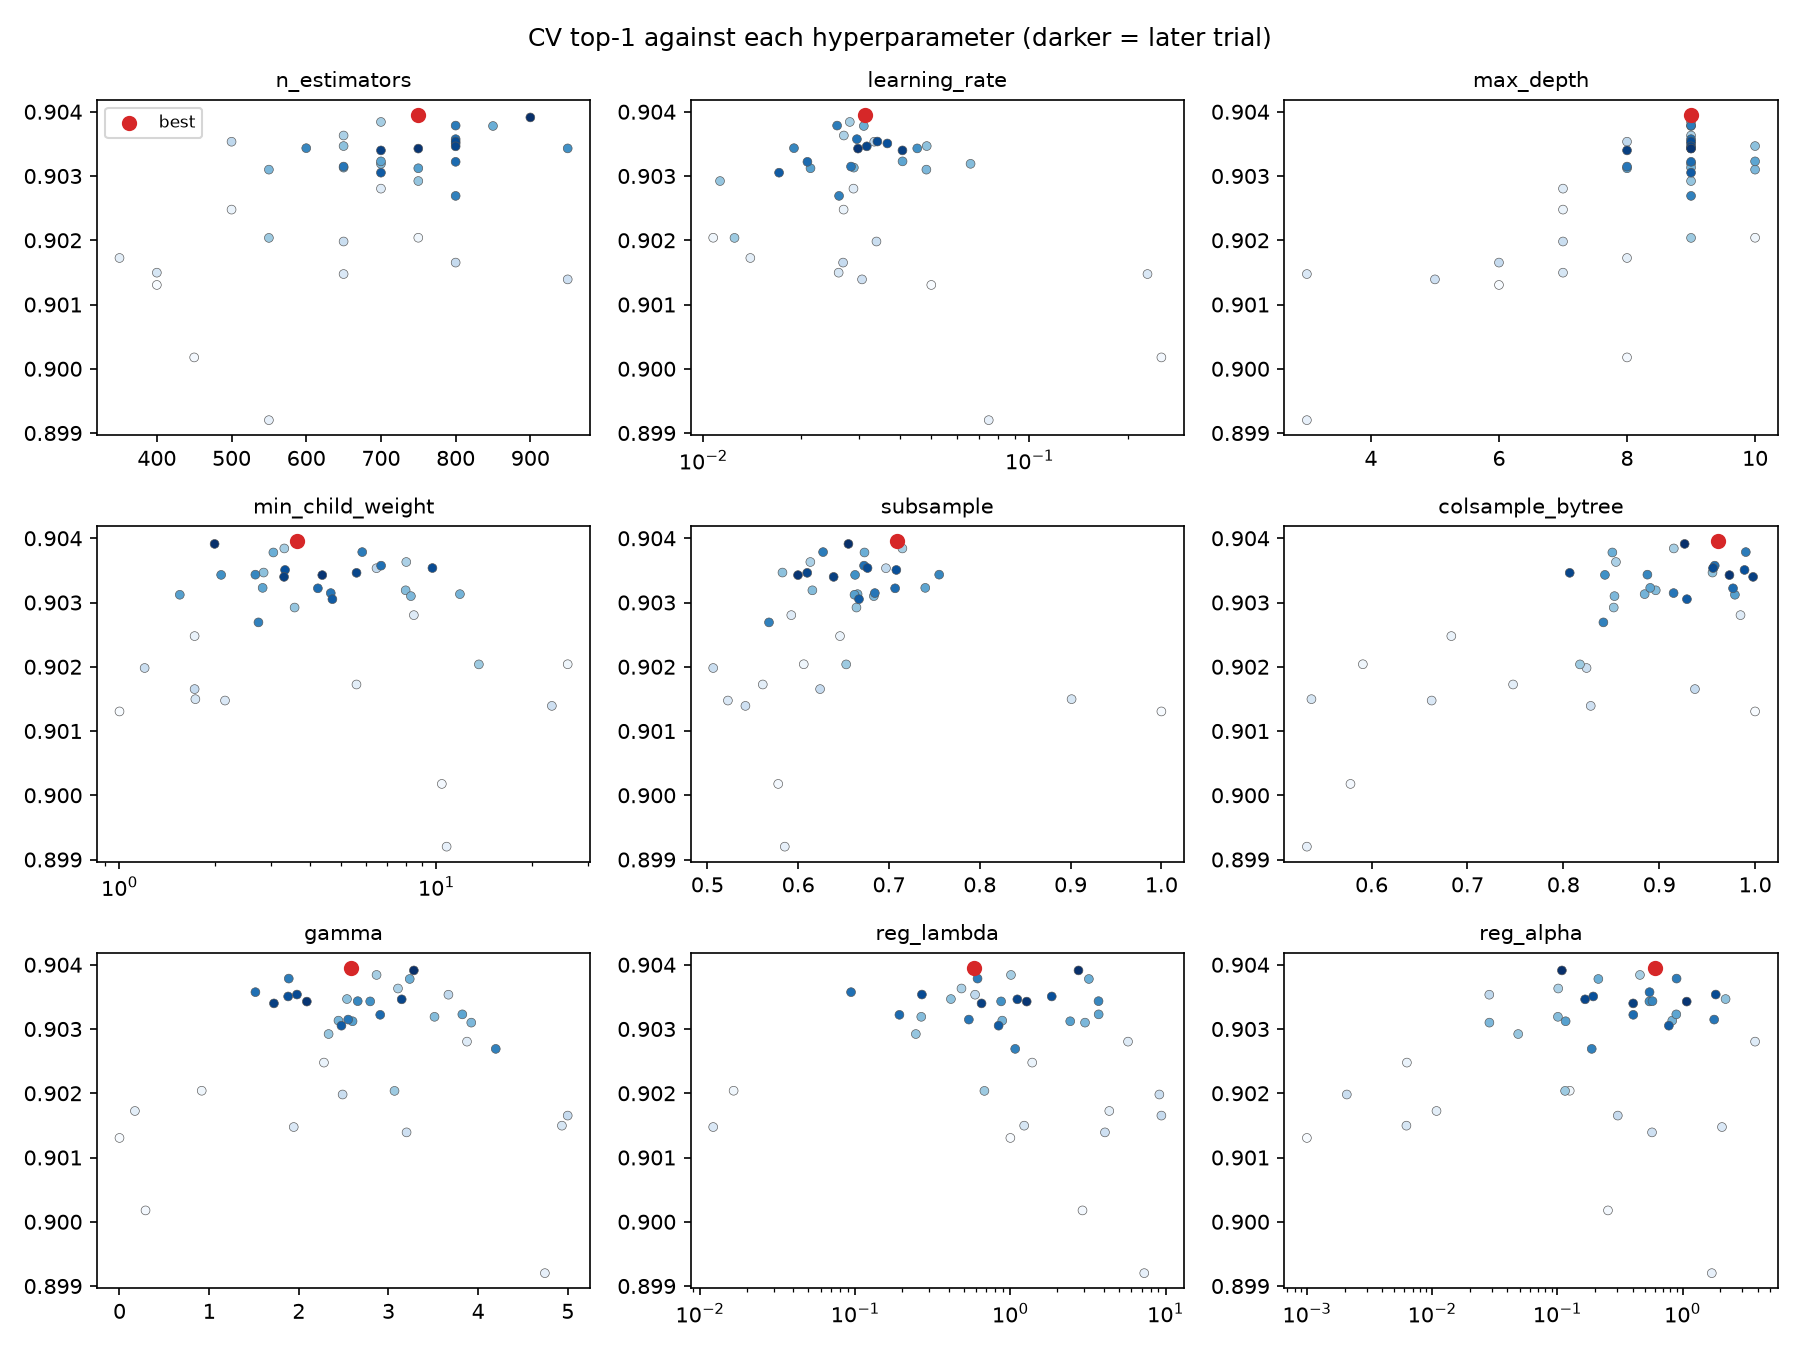

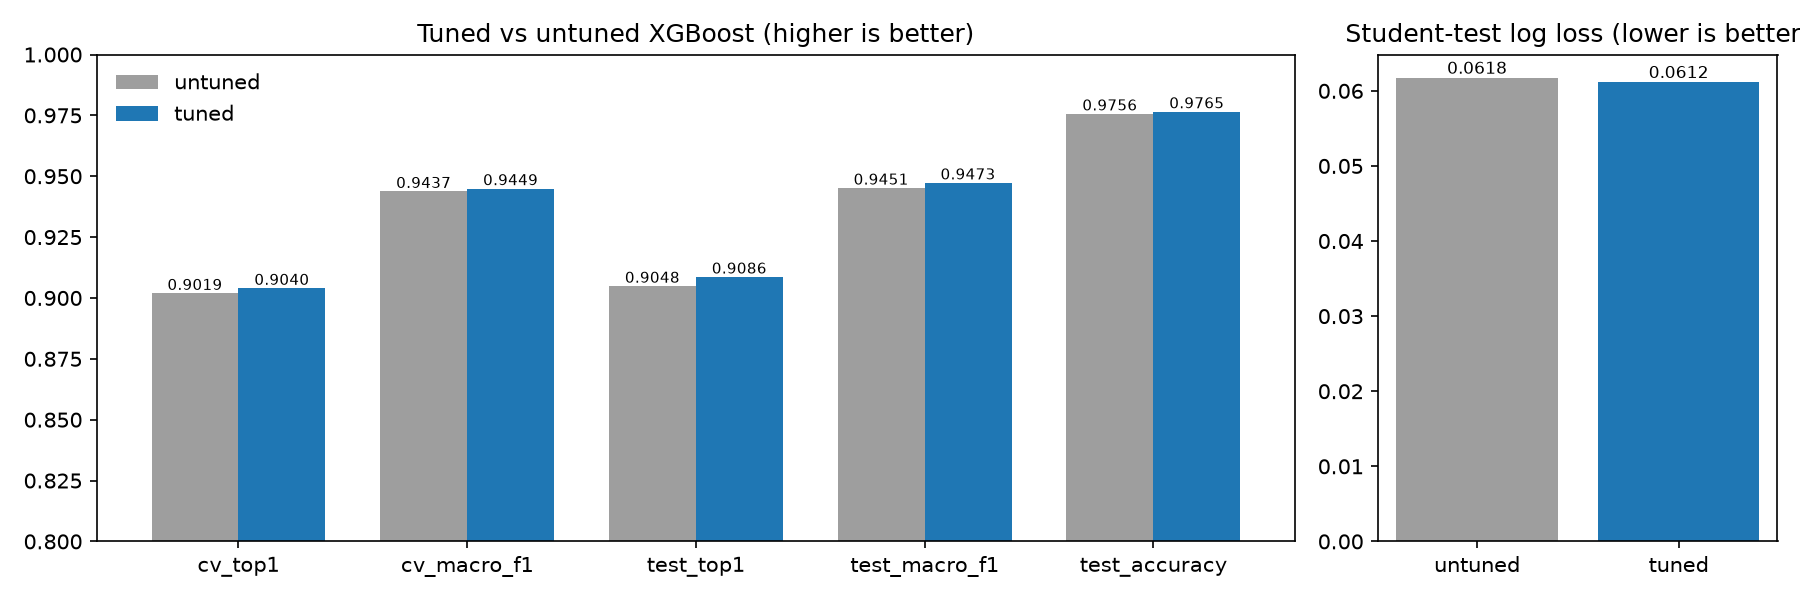

In [5]:
hpo_plots.main()
for f in ["optimisation_history.png", "param_importance.png", "param_slices.png", "tuned_vs_untuned.png"]:
    display(Image(filename=str(H / "plots" / f)))

## 5. Tuned vs untuned (same folds, same student-test trips)

The tuned model is refitted through the same harness as every other model (`python -m pathsnap.hpo.xgb_optuna --refit`).

In [6]:
cmp = pd.read_csv(H / "xgb_tuned_vs_untuned.csv").set_index("model")
diff = (cmp.loc["tuned"] - cmp.loc["untuned"]).rename("tuned - untuned")
pd.concat([cmp.T, diff], axis=1).round(4)

,untuned,tuned,tuned - untuned
cv_macro_f1,0.9437,0.9449,0.0011
cv_top1,0.9019,0.9040,0.0021
cv_log_loss,0.0694,0.0690,-0.0003
test_top1,0.9048,0.9086,0.0038
test_accuracy,0.9756,0.9765,0.0009
test_macro_f1,0.9451,0.9473,0.0021
test_log_loss,0.0618,0.0612,-0.0006
test_route_continuity,0.9573,0.9588,0.0015
fit_seconds,19.0551,38.3263,19.2712
inference_ms_per_1000_points,10.2273,35.0802,24.8529


## 6. Why tuning adds so little: where the remaining errors are

All models score within a narrow Top-1 band (notebook 03), so the ceiling comes from the data, not from XGBoost settings.
Each student-test point is classified by how the predicted arc relates to the reference arc
(`python -m pathsnap.models.error_analysis`).

In [7]:
from pathsnap.models.error_analysis import breakdown
from pathsnap.config import ARTIFACTS_DIR
eb = breakdown(ARTIFACTS_DIR / "final_model.joblib", "final_model")


[final_model] 19133 student_test points -> /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/results/models/error_breakdown_final_model.csv
                          points  share_pct  gps_heading_agrees_with_prediction_pct
category                                                                           
correct                    17384      90.86                                     NaN
reverse twin                 737       3.85                                    55.9
next/previous arc            367       1.92                                     NaN
sibling at same junction     333       1.74                                     NaN
other road                   297       1.55                                     NaN
label not a candidate         15       0.08                                     NaN


- **reverse twin**: same street, opposite direction. In most of these the GPS travel direction agrees with the
  *prediction*, not with the reference arc, so they point to direction noise in the reference route rather than
  model errors.
- **next/previous arc** and **sibling at same junction**: the point lies at a junction where two arcs meet;
  either answer is geometrically defensible.
- **other road**: genuinely wrong roads.
- **label not a candidate**: unrecoverable by any classifier (candidate miss rate).

Sequence information (HMM/Viterbi, next stage) targets the junction and other-road errors by enforcing
connected routes.

## 7. Computational cost

Total search time is the sum of trial durations above (5 fits per completed trial, fewer for pruned ones,
16 CPU threads). The final refit is a single fit on all train trips. The tuned model is saved as
`artifacts/final_model.joblib` with its parameters in `artifacts/final_model.json`, for the HMM decoder and the API.